# Лабораторная работа 4: обнаружение аномалий в данных телеметрии

**Задача.** На вход подаётся массив показаний датчика (.csv), на выходе получается массив той же длины из 0 и 1: 1 — показание аномальное (сбой датчика или оборудования).

**Данные.** [Sensor Fault Detection Data](https://www.kaggle.com/datasets/arashnic/sensor-fault-detection-data): один датчик температуры, около 62 тысяч показаний с августа 2016 по август 2017, обычно раз в 5 минут. **Разметки аномалий в данных нет**, поэтому обучение идёт без учителя: модель учится на обычных данных и отмечает то, что на них не похоже.

**Подход.**
- **LSTM-автокодировщик.** Нейросеть сжимает отрезок из 48 показаний (4 часа) в 16 чисел и восстанавливает его обратно. Обычное поведение датчика она восстанавливает хорошо, а необычное — плохо. Большая ошибка восстановления = аномалия.
- **Фильтр Хампеля** (для сравнения) — простой статистический метод: показание аномально, если сильно отличается от медианы соседних показаний.

**Оценка.** Раз настоящей разметки нет, в проверочную часть данных вставляются **искусственные сбои** четырёх типов: скачок, «залипание» значения, дрейф, шум. Для них считаются precision, recall, F1, ROC-AUC и PR-AUC.

## 1. Подготовка

In [3]:
import os
import random
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

# Вычисления на видеокарте
DEVICE = torch.device("cuda")

# Одинаковые случайные числа при каждом запуске
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Папка для весов модели
CKPT_DIR = Path("checkpoints")
# Папка для размеченного результата
RESULTS_DIR = Path("results")
for folder in (CKPT_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Шаг равномерной сетки времени
STEP = "5min"
# Длина отрезка, который видит автокодировщик: 48 шагов по 5 минут = 4 часа
WINDOW = 48
# Пропуски не длиннее 12 шагов (1 час) заполняются прямой линией, более длинные разрывают ряд на куски
MAX_GAP_STEPS = 12
# Доля данных (по времени) для обучения; остальное — для проверки
TRAIN_SHARE = 0.7

## 2. Данные

In [4]:
def read_telemetry(df):
    # Приводит таблицу показаний (столбцы Timestamp;SensorId;Value) к рабочему виду:
    # время переводится в московское, строки сортируются по времени
    df = df.copy()
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], utc=True).dt.tz_convert("Europe/Moscow").dt.tz_localize(None)
    return df.sort_values("Timestamp").reset_index(drop=True)


# Чтение CSV из архива
with zipfile.ZipFile(Path("..", "..", "sensor-fault-detection.zip")) as archive:
    csv_name = next(n for n in archive.namelist() if n.lower().endswith(".csv"))
    with archive.open(csv_name) as f:
        raw = read_telemetry(pd.read_csv(f, sep=";"))

print(f"Показаний: {len(raw)}, период: {raw['Timestamp'].min()} — {raw['Timestamp'].max()}")

Показаний: 62629, период: 2016-08-01 01:00:00 — 2017-09-01 00:55:00


Точек сетки: 114048, из них с данными: 95432
Непрерывных кусков: 63
Обучение: 2016-08-01 01:00:00 — 2017-05-05 05:40:00
Проверка: 2017-05-05 05:45:00 — 2017-09-01 00:55:00


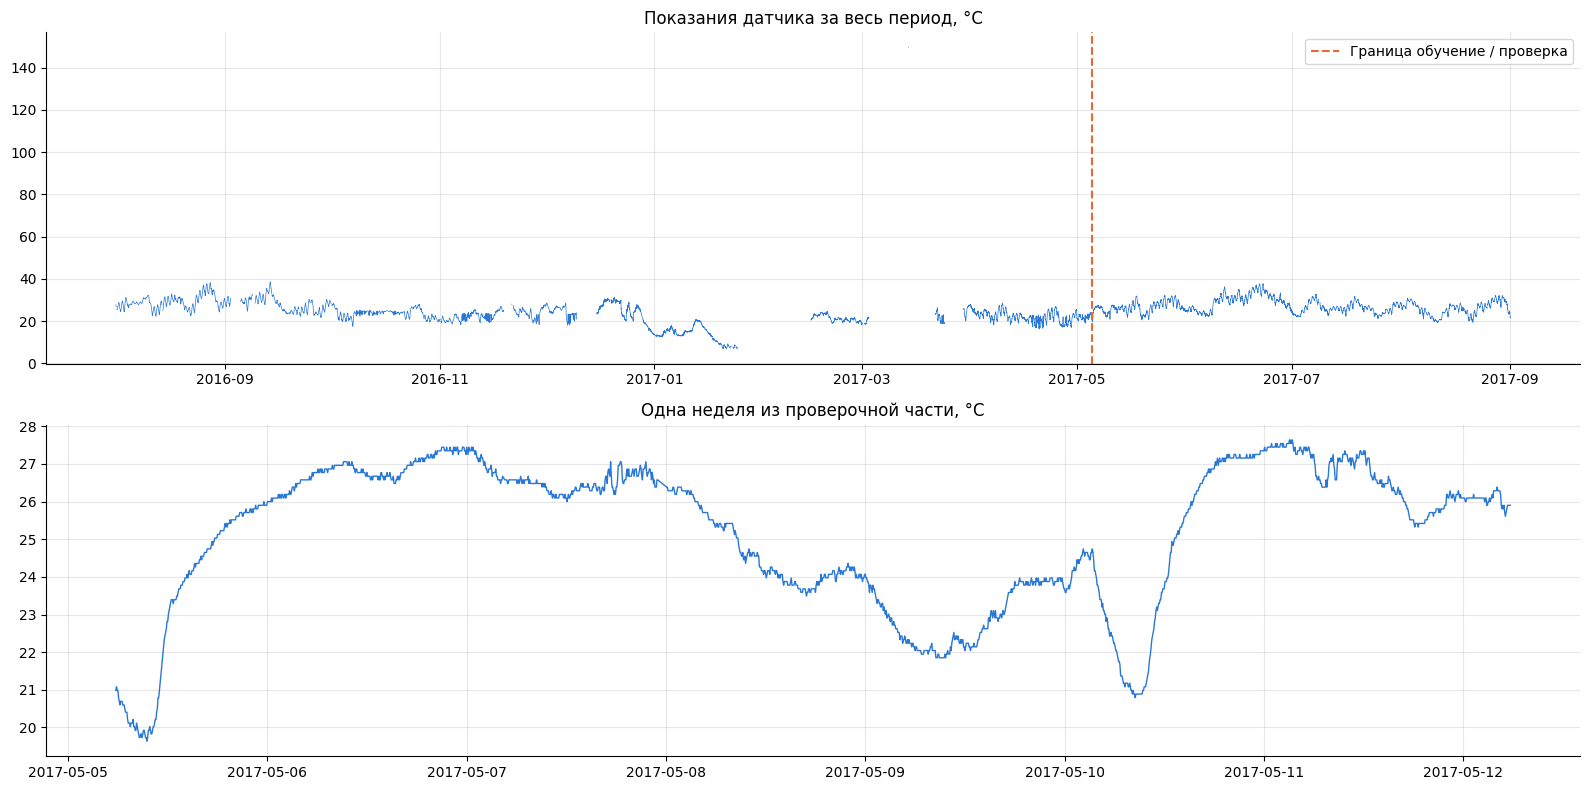

In [5]:
def fill_short_gaps(series, max_len):
    # Заполняет прямой линией только короткие пропуски (не длиннее max_len шагов); длинные остаются пустыми
    is_nan = series.isna()
    gap_id = (~is_nan).cumsum()
    gap_len = is_nan.groupby(gap_id).transform("sum")
    filled = series.interpolate(limit_area="inside")
    return filled.where(~is_nan | (gap_len <= max_len))


def to_grid(df):
    # Переводит показания на равномерную сетку времени с шагом STEP: несколько показаний в одном шаге усредняются
    series = df.set_index("Timestamp")["Value"].resample(STEP).mean()
    return fill_short_gaps(series, MAX_GAP_STEPS)


def segments(values):
    # Возвращает список (начало, конец) непрерывных кусков ряда без пропусков
    valid = ~np.isnan(values)
    edges = np.diff(np.concatenate([[0], valid.astype(int), [0]]))
    return list(zip(np.where(edges == 1)[0], np.where(edges == -1)[0]))


grid = to_grid(raw)
values = grid.to_numpy()
times = grid.index

# Деление по времени: обучение на ранних данных, проверка на поздних
split = int(len(values) * TRAIN_SHARE)
train_values, test_values = values[:split], values[split:]
print(f"Точек сетки: {len(values)}, из них с данными: {np.isfinite(values).sum()}")
print(f"Непрерывных кусков: {len(segments(values))}")
print(f"Обучение: {times[0]} — {times[split - 1]}")
print(f"Проверка: {times[split]} — {times[-1]}")

# Средняя температура и разброс на обучающей части: по ним показания приводятся к масштабу около 0 ± 1
MEAN = np.nanmean(train_values)
STD = np.nanstd(train_values)

# Весь ряд целиком и одна неделя крупно
fig, axes = plt.subplots(2, 1, figsize=(16, 8))
axes[0].plot(times, values, color="#2a78d6", lw=0.5)
axes[0].axvline(times[split], color="#eb6834", ls="--", lw=1.5, label="Граница обучение / проверка")
axes[0].set_title("Показания датчика за весь период, °C")
axes[0].legend()
week = (times >= times[split]) & (times < times[split] + pd.Timedelta(days=7))
axes[1].plot(times[week], values[week], color="#2a78d6", lw=1)
axes[1].set_title("Одна неделя из проверочной части, °C")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Искусственные сбои в проверочной части

Четыре типичных вида неисправности датчика:
- **скачок** — одно показание резко отличается от соседних (помеха, сбой передачи);
- **залипание** — датчик несколько часов присылает одно и то же значение;
- **дрейф** — показания постепенно «уплывают» от настоящих (старение, загрязнение датчика);
- **шум** — показания начинают сильно дрожать (плохой контакт).

Вставлено сбоев: 80, точек со сбоем: 3864 из 33860


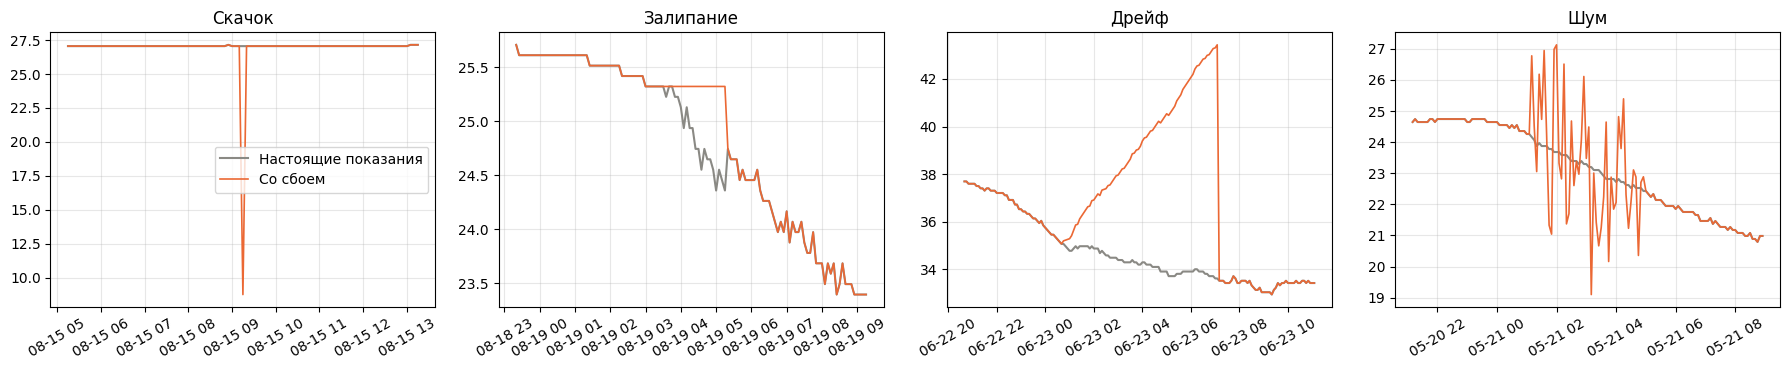

In [6]:
# Виды сбоев и количество сбоев каждого вида
FAULT_KINDS = ["скачок", "залипание", "дрейф", "шум"]
FAULTS_PER_KIND = 20


def inject_faults(values, rng):
    # Вставляет искусственные сбои в копию ряда.
    # Возвращает ряд со сбоями, метки (1 — точка внутри сбоя) и список сбоев (вид, начало, длина)
    faulty = values.copy()
    labels = np.zeros(len(values), dtype=int)
    events = []
    long_segments = [(a, b) for a, b in segments(values) if b - a >= 6 * WINDOW]

    def pick_start(length):
        # Случайное место для сбоя: внутри непрерывного куска, с запасом от его краёв и от других сбоев
        for _ in range(10_000):
            a, b = long_segments[rng.integers(len(long_segments))]
            start = int(rng.integers(a + WINDOW, b - WINDOW - length))
            if not labels[start - WINDOW:start + length + WINDOW].any():
                return start
        raise RuntimeError("Не нашлось места для сбоя")

    for kind in FAULT_KINDS:
        for _ in range(FAULTS_PER_KIND):
            sign = rng.choice([-1, 1])
            if kind == "скачок":
                # Одно показание на 8–20 °C выше или ниже настоящего
                length = 1
                start = pick_start(length)
                faulty[start] += sign * rng.uniform(8, 20)
            elif kind == "залипание":
                # Значение не меняется 2–6 часов
                length = int(rng.integers(24, 73))
                start = pick_start(length)
                faulty[start:start + length] = faulty[start]
            elif kind == "дрейф":
                # Ошибка плавно растёт до 5–10 °C за 6–12 часов
                length = int(rng.integers(72, 145))
                start = pick_start(length)
                faulty[start:start + length] += sign * np.linspace(0, rng.uniform(5, 10), length)
            else:
                # Случайная дрожь с разбросом 2 °C в течение 2–4 часов
                length = int(rng.integers(24, 49))
                start = pick_start(length)
                faulty[start:start + length] += rng.normal(0, 2.0, length)
            labels[start:start + length] = 1
            events.append((kind, start, length))
    return faulty, labels, events


rng = np.random.default_rng(42)
test_faulty, test_labels, test_events = inject_faults(test_values, rng)
print(f"Вставлено сбоев: {len(test_events)}, точек со сбоем: {test_labels.sum()} из {np.isfinite(test_values).sum()}")

# По одному примеру каждого вида
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, kind in zip(axes, FAULT_KINDS):
    _, start, length = next(e for e in test_events if e[0] == kind)
    part = slice(start - WINDOW, start + length + WINDOW)
    ax.plot(times[split:][part], test_values[part], color="#8a8984", lw=1.5, label="Настоящие показания")
    ax.plot(times[split:][part], test_faulty[part], color="#eb6834", lw=1.2, label="Со сбоем")
    ax.set_title(kind.capitalize())
    ax.tick_params(axis="x", labelrotation=30)
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

## 4. Модели

In [7]:
class LSTMAutoencoder(nn.Module):
    # Автокодировщик: LSTM-кодировщик сжимает отрезок ряда в короткий вектор, LSTM-декодер восстанавливает отрезок обратно

    def __init__(self, hidden=64, latent=16):
        # hidden — размер памяти LSTM, latent — во сколько чисел сжимается отрезок
        super().__init__()
        self.encoder = nn.LSTM(1, hidden, num_layers=2, batch_first=True)
        self.to_latent = nn.Linear(hidden, latent)
        self.from_latent = nn.Linear(latent, hidden)
        self.decoder = nn.LSTM(hidden, hidden, num_layers=2, batch_first=True)
        self.output = nn.Linear(hidden, 1)

    def forward(self, x):
        # x — отрезки формы (порция, WINDOW); на выходе — восстановленные отрезки той же формы
        _, (h, _) = self.encoder(x.unsqueeze(-1))
        z = self.to_latent(h[-1])
        # Сжатый вектор подаётся декодеру на каждом шаге отрезка
        decoder_input = self.from_latent(z).unsqueeze(1).repeat(1, x.shape[1], 1)
        y, _ = self.decoder(decoder_input)
        return self.output(y).squeeze(-1)


def make_windows(values, stride):
    # Нарезает непрерывные куски ряда на отрезки длины WINDOW с шагом stride.
    # Возвращает отрезки (уже в масштабе 0 ± 1) и номера их первых точек в ряду
    windows, starts = [], []
    for a, b in segments(values):
        if b - a < WINDOW:
            continue
        s = np.arange(a, b - WINDOW + 1, stride)
        starts.append(s)
        windows.append(np.stack([values[i:i + WINDOW] for i in s]))
    windows = (np.concatenate(windows) - MEAN) / STD
    return windows.astype(np.float32), np.concatenate(starts)


@torch.no_grad()
def autoencoder_scores(model, values, batch=4096):
    # Оценка аномальности каждой точки: средний квадрат ошибки восстановления этой точки по всем отрезкам, куда она попала.
    # Точки в пропусках и в кусках короче WINDOW получают NaN
    model.eval()
    windows, starts = make_windows(values, stride=1)
    errors = []
    for i in range(0, len(windows), batch):
        x = torch.from_numpy(windows[i:i + batch]).to(DEVICE)
        errors.append(((model(x) - x) ** 2).cpu().numpy())
    errors = np.concatenate(errors)

    # Сложение ошибок по точкам: точка start + j получает ошибку j-й позиции отрезка
    sums = np.zeros(len(values))
    counts = np.zeros(len(values))
    idx = starts[:, None] + np.arange(WINDOW)
    np.add.at(sums, idx, errors)
    np.add.at(counts, idx, 1)
    with np.errstate(invalid="ignore"):
        return np.where(counts > 0, sums / counts, np.nan)


# Половина ширины окна фильтра Хампеля: 12 шагов в каждую сторону = ±1 час
HAMPEL_HALF = 12
# Наименьший учитываемый разброс, °C: шаг измерения датчика около 0.1 °C, меньшие разбросы — это ровный участок
MAD_FLOOR = 0.1


def hampel_scores(values):
    # Оценка аномальности по фильтру Хампеля: во сколько раз точка дальше от медианы соседей, чем их обычный разброс
    s = pd.Series(values)
    size = 2 * HAMPEL_HALF + 1
    median = s.rolling(size, center=True, min_periods=HAMPEL_HALF + 1).median()
    deviation = (s - median).abs()
    # Медиана отклонений (MAD), умноженная на 1.4826, сравнима со стандартным отклонением
    mad = deviation.rolling(size, center=True, min_periods=HAMPEL_HALF + 1).median()
    return (deviation / (1.4826 * np.maximum(mad, MAD_FLOOR))).to_numpy()


model = LSTMAutoencoder().to(DEVICE)

## 5. Обучение автокодировщика

In [8]:
def save_state(path, state):
    # Сохраняет состояние обучения через временный файл, прерванная запись не портит прошлое сохранение
    tmp_path = path.with_name(path.name + ".tmp")
    torch.save(state, tmp_path)
    os.replace(tmp_path, path)


# Отрезки из обучающей части с шагом 2; последние 10% (по времени) — для контроля переобучения
train_windows, _ = make_windows(train_values, stride=2)
n_val = len(train_windows) // 10
fit_windows, val_windows = train_windows[:-n_val], train_windows[-n_val:]
print(f"Отрезков для обучения: {len(fit_windows)}, для контроля: {len(val_windows)}")

# Количество эпох и размер порции
EPOCHS = 30
BATCH_SIZE = 256

fit_loader = DataLoader(TensorDataset(torch.from_numpy(fit_windows)), batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_tensor = torch.from_numpy(val_windows).to(DEVICE)

mse_loss = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# Плавное снижение скорости обучения к концу
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

# История обучения: ошибка на обучающих и контрольных отрезках после каждой эпохи
history = []
state_path = CKPT_DIR / "lstm_autoencoder_state.pth"
start_epoch = 1

# Продолжение с места остановки, если есть сохранение
if state_path.exists():
    state = torch.load(state_path, map_location="cpu")
    model.load_state_dict(state["model"])
    optimizer.load_state_dict(state["optimizer"])
    scheduler.load_state_dict(state["scheduler"])
    history = state["history"]
    start_epoch = state["epoch"] + 1
    print(f"Найдено сохранение {state_path.name}: пройдено эпох {state['epoch']} из {EPOCHS}")
    del state

for epoch in range(start_epoch, EPOCHS + 1):
    start = time.time()
    model.train()
    total = 0.0
    for (x,) in fit_loader:
        x = x.to(DEVICE, non_blocking=True)
        loss = mse_loss(model(x), x)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item()
    scheduler.step()

    model.eval()
    with torch.no_grad():
        val_loss = mse_loss(model(val_tensor), val_tensor).item()
    history.append((total / len(fit_loader), val_loss))

    # Сохранение всего состояния обучения после каждой эпохи
    save_state(state_path, {
        "epoch": epoch,
        "history": history,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
    })
    print(f"Эпоха {epoch:2d}: ошибка {total / len(fit_loader):.5f}, на контроле {val_loss:.5f}, {time.time() - start:.1f} с")

Отрезков для обучения: 26810, для контроля: 2978
Эпоха  1: ошибка 0.21579, на контроле 0.04737, 4.5 с
Эпоха  2: ошибка 0.02155, на контроле 0.04310, 1.9 с
Эпоха  3: ошибка 0.01639, на контроле 0.03847, 1.9 с
Эпоха  4: ошибка 0.01199, на контроле 0.03049, 2.1 с
Эпоха  5: ошибка 0.00984, на контроле 0.02137, 3.2 с
Эпоха  6: ошибка 0.00680, на контроле 0.02000, 2.2 с
Эпоха  7: ошибка 0.00650, на контроле 0.01965, 2.2 с
Эпоха  8: ошибка 0.00637, на контроле 0.02007, 2.3 с
Эпоха  9: ошибка 0.00631, на контроле 0.01948, 2.3 с
Эпоха 10: ошибка 0.00626, на контроле 0.01936, 2.0 с
Эпоха 11: ошибка 0.00625, на контроле 0.01931, 2.1 с
Эпоха 12: ошибка 0.00616, на контроле 0.01931, 2.1 с
Эпоха 13: ошибка 0.00611, на контроле 0.01930, 2.4 с
Эпоха 14: ошибка 0.00611, на контроле 0.01925, 2.1 с
Эпоха 15: ошибка 0.00608, на контроле 0.01920, 2.0 с
Эпоха 16: ошибка 0.00607, на контроле 0.01920, 2.1 с
Эпоха 17: ошибка 0.00605, на контроле 0.01915, 2.4 с
Эпоха 18: ошибка 0.00604, на контроле 0.01916, 2.5

## 6. Пороги и оценка на искусственных сбоях

Порог для каждого метода выбирается **только по обучающим данным**: точка считается аномалией, если её оценка выше, чем у 99.5% обучающих точек. Проверочные данные при выборе порога не используются.

In [9]:
# Доля обучающих точек, которые считаются нормальными
THRESHOLD_QUANTILE = 0.995

detectors = {"LSTM-автокодировщик": lambda v: autoencoder_scores(model, v), "Фильтр Хампеля": hampel_scores}

thresholds, test_scores = {}, {}
for name, detector in detectors.items():
    thresholds[name] = np.nanquantile(detector(train_values), THRESHOLD_QUANTILE)
    test_scores[name] = detector(test_faulty)
    print(f"{name}: порог {thresholds[name]:.4f}")

# Точки, где оценка есть у обоих методов: метрики считаются по одним и тем же точкам
mask = np.all([np.isfinite(s) for s in test_scores.values()], axis=0)
y_true = test_labels[mask]
print(f"Точек в оценке: {mask.sum()}, из них со сбоем: {y_true.sum()}")

# Итоговая таблица: для всех метрик больше — лучше
print(f"\n{'Метод':<22}{'Precision':>11}{'Recall':>9}{'F1':>8}{'ROC-AUC':>10}{'PR-AUC':>9}")
predictions = {}
for name, scores in test_scores.items():
    predictions[name] = (scores > thresholds[name]).astype(int)
    y_pred, y_score = predictions[name][mask], scores[mask]
    print(f"{name:<22}{precision_score(y_true, y_pred):>11.3f}{recall_score(y_true, y_pred):>9.3f}"
          f"{f1_score(y_true, y_pred):>8.3f}{roc_auc_score(y_true, y_score):>10.3f}"
          f"{average_precision_score(y_true, y_score):>9.3f}")

# Сколько сбоев каждого вида найдено: сбой найден, если отмечена хотя бы одна его точка
print(f"\nНайдено сбоев (из {FAULTS_PER_KIND} каждого вида):")
print(f"{'Вид':<12}" + "".join(f"{name:>22}" for name in detectors))
for kind in FAULT_KINDS:
    row = f"{kind:<12}"
    for name in detectors:
        found = sum(predictions[name][s:s + n].any() for k, s, n in test_events if k == kind)
        row += f"{found:>22}"
    print(row)

LSTM-автокодировщик: порог 0.1152
Фильтр Хампеля: порог 2.5998
Точек в оценке: 33857, из них со сбоем: 3864

Метод                   Precision   Recall      F1   ROC-AUC   PR-AUC
LSTM-автокодировщик         0.640    0.179   0.280     0.842    0.563
Фильтр Хампеля              0.765    0.062   0.114     0.564    0.224

Найдено сбоев (из 20 каждого вида):
Вид            LSTM-автокодировщик        Фильтр Хампеля
скачок                          20                    20
залипание                        0                     0
дрейф                           20                    16
шум                             20                    20


## 7. Визуальное сравнение

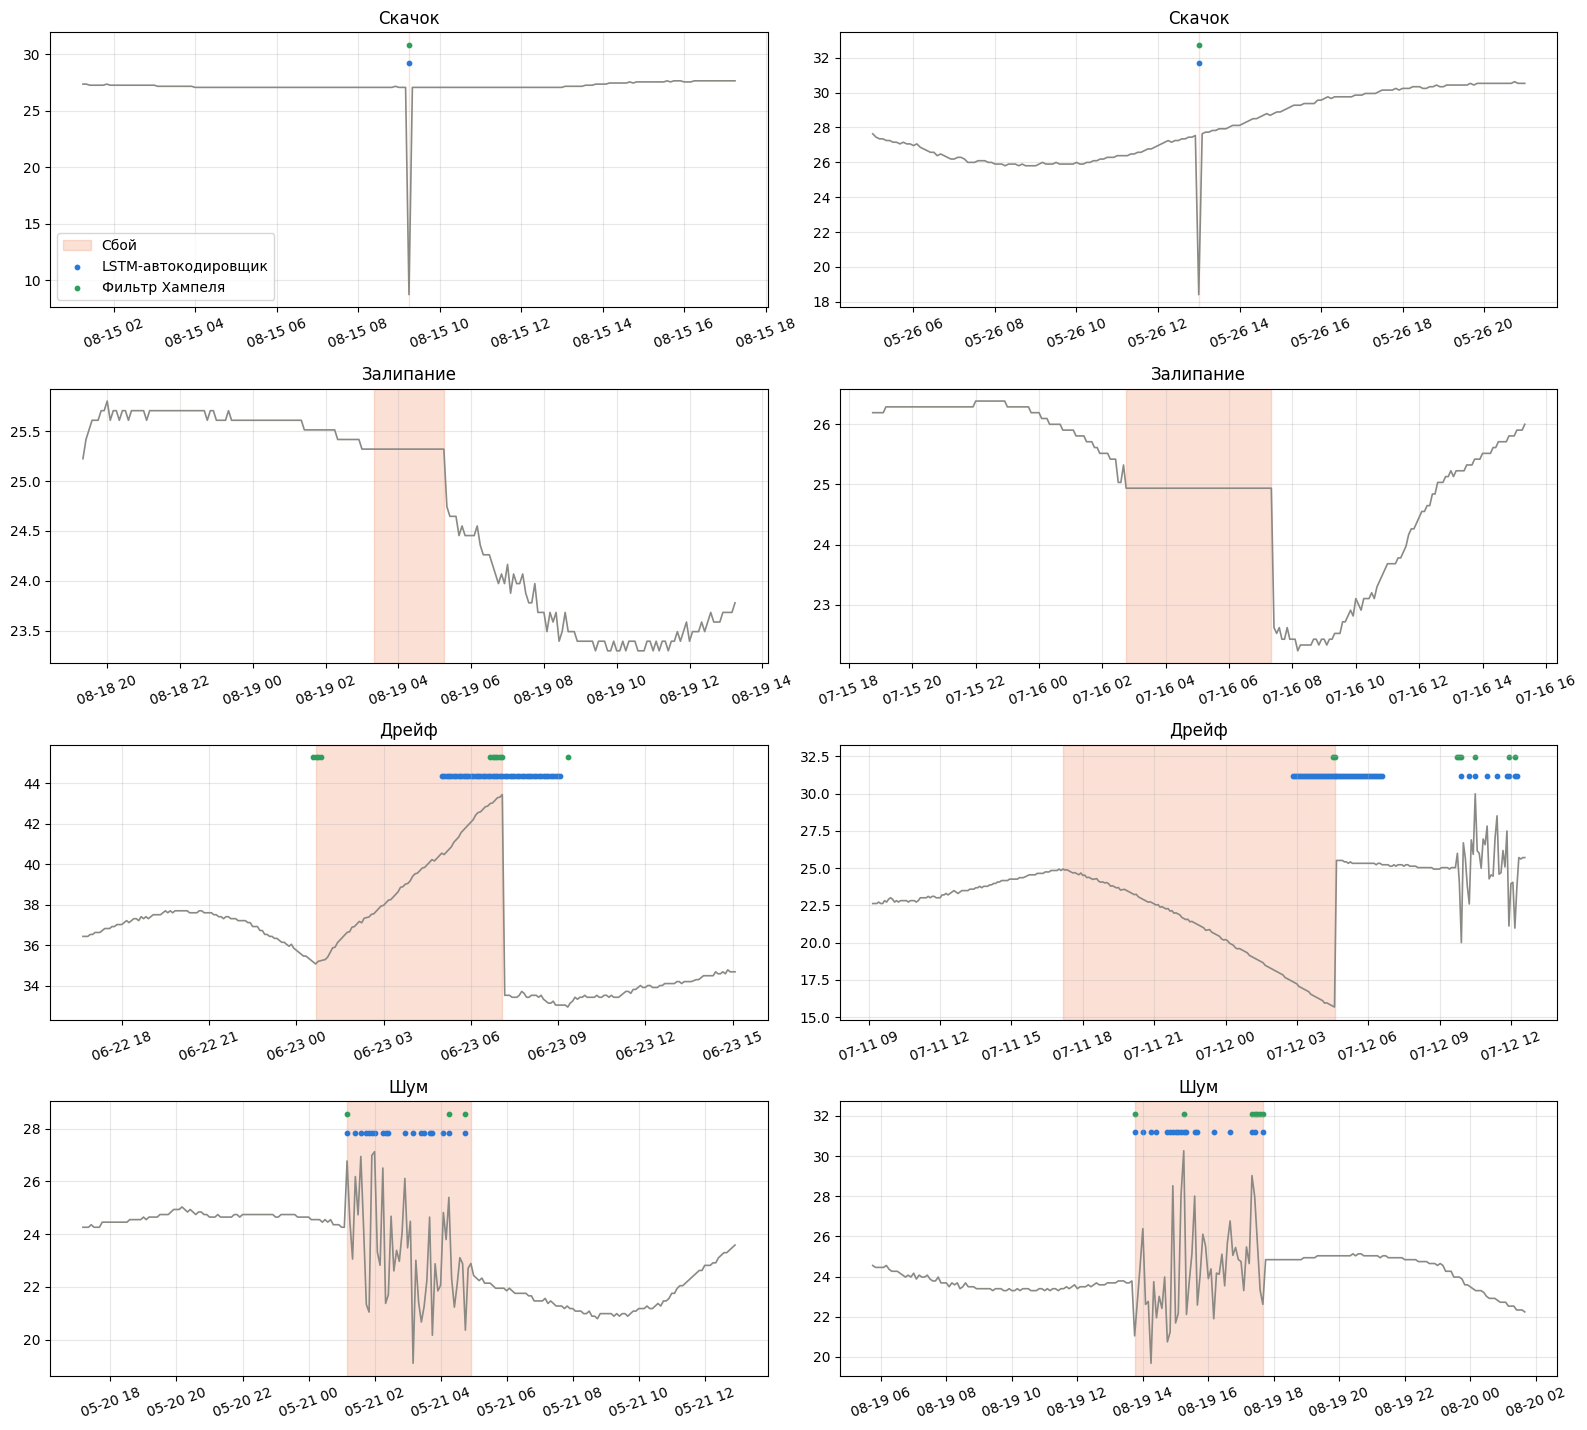

In [10]:
# Цвета: серый — показания, оранжевый — участок со сбоем, синий и зелёный — отметки методов
COLOR_SERIES, COLOR_FAULT = "#8a8984", "#eb6834"
METHOD_COLORS = {"LSTM-автокодировщик": "#2a78d6", "Фильтр Хампеля": "#2e9e5b"}

# Для каждого вида сбоя — два примера; точки, отмеченные методами, показаны маркерами на разной высоте
fig, axes = plt.subplots(len(FAULT_KINDS), 2, figsize=(16, 3.6 * len(FAULT_KINDS)))
test_times = times[split:]
for row, kind in zip(axes, FAULT_KINDS):
    kind_events = [e for e in test_events if e[0] == kind][:2]
    for ax, (_, start, length) in zip(row, kind_events):
        part = slice(start - 2 * WINDOW, start + length + 2 * WINDOW)
        t, v = test_times[part], test_faulty[part]
        ax.plot(t, v, color=COLOR_SERIES, lw=1.2)
        ax.axvspan(test_times[start], test_times[start + length - 1], color=COLOR_FAULT, alpha=0.2, label="Сбой")
        low, high = np.nanmin(v), np.nanmax(v)
        for k, (name, pred) in enumerate(predictions.items()):
            flagged = pred[part] == 1
            ax.scatter(t[flagged], np.full(flagged.sum(), high + (k + 1) * 0.08 * (high - low + 1)),
                       color=METHOD_COLORS[name], s=10, label=name)
        ax.set_title(kind.capitalize())
        ax.tick_params(axis="x", labelrotation=20)
        ax.grid(alpha=0.3)
axes[0, 0].legend(loc="lower left")
plt.tight_layout()
plt.show()

## 8. Графики обучения и распределение оценок

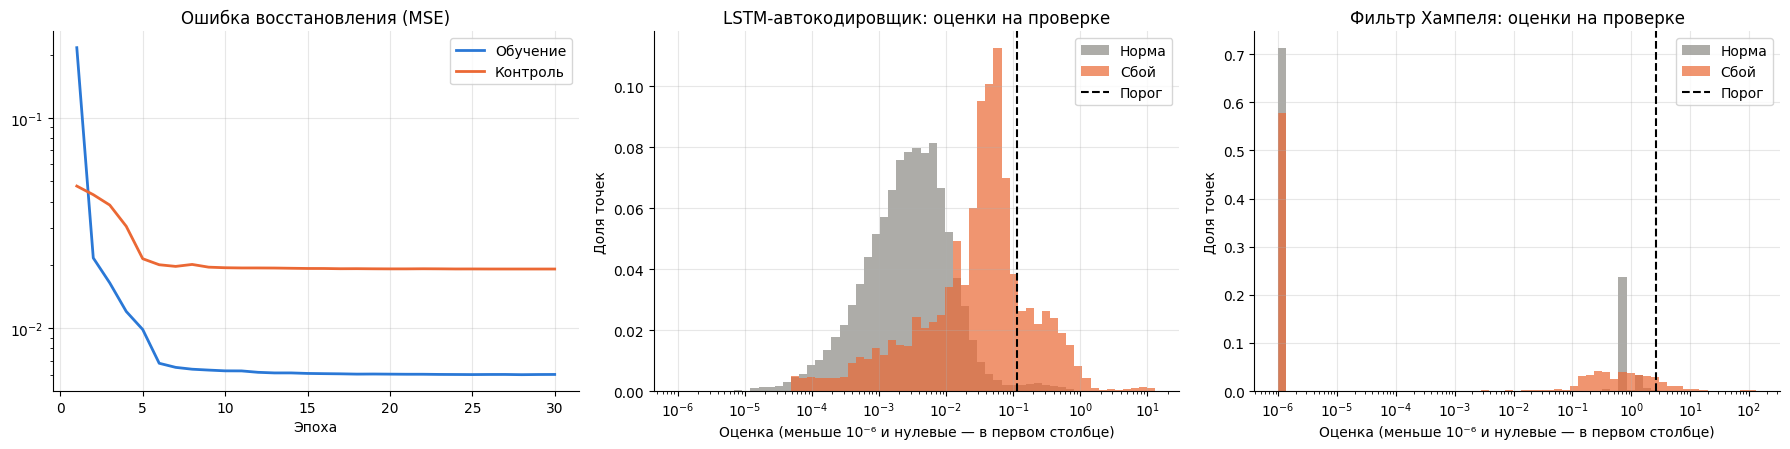

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))

# Ошибка автокодировщика по эпохам
ax = axes[0]
ax.plot(range(1, EPOCHS + 1), [h[0] for h in history], color="#2a78d6", lw=2, label="Обучение")
ax.plot(range(1, EPOCHS + 1), [h[1] for h in history], color="#eb6834", lw=2, label="Контроль")
ax.set_yscale("log")
ax.set_title("Ошибка восстановления (MSE)")
ax.set_xlabel("Эпоха")
ax.legend()

# Наименьшая показываемая оценка
SCORE_FLOOR = 1e-6

# Распределение оценок для нормальных точек и точек со сбоем; вертикальная линия — порог
for ax, name in zip(axes[1:], detectors):
    # Оценки меньше SCORE_FLOOR, в том числе нулевые, собираются в первый столбец
    scores = np.clip(test_scores[name][mask], SCORE_FLOOR, None)
    bins = np.logspace(np.log10(SCORE_FLOOR), np.log10(scores.max()), 60)
    for part, color, label in [(scores[y_true == 0], COLOR_SERIES, "Норма"), (scores[y_true == 1], COLOR_FAULT, "Сбой")]:
        # Высота столбца — доля точек группы, попавших в столбец
        ax.hist(part, bins=bins, weights=np.full(len(part), 1 / len(part)), color=color, alpha=0.7, label=label)
    ax.axvline(thresholds[name], color="black", ls="--", lw=1.5, label="Порог")
    ax.set_xscale("log")
    ax.set_xlabel("Оценка (меньше 10⁻⁶ и нулевые — в первом столбце)")
    ax.set_ylabel("Доля точек")
    ax.set_title(f"{name}: оценки на проверке")
    ax.legend()

for ax in axes:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 9. Разметка настоящих данных

Оба метода применяются ко всему исходному ряду (без искусственных сбоев). Результат — столбец из 0 и 1 для каждого исходного показания:
- `anomaly` — отметка LSTM-автокодировщика (основной результат);
- `anomaly_hampel` — отметка фильтра Хампеля для сравнения.

Показания из кусков короче 4 часов автокодировщик оценить не может, для них `anomaly` = 0.

Отмечено аномалий: автокодировщик 238, фильтр Хампеля 323 из 62629 показаний

Самые большие и самые маленькие отмеченные автокодировщиком показания:
          Timestamp     Value
2017-04-20 06:10:00 16.169497
2017-04-20 06:05:00 16.169497
2017-04-20 06:00:00 16.265728
2017-04-20 06:15:00 16.265728
2017-04-20 05:55:00 16.361980
2017-03-22 09:40:00 26.286133
2016-12-06 20:00:00 28.119251
2017-07-09 00:15:00 28.891314
2016-12-22 11:25:00 29.373913
2016-12-22 11:20:00 29.856590


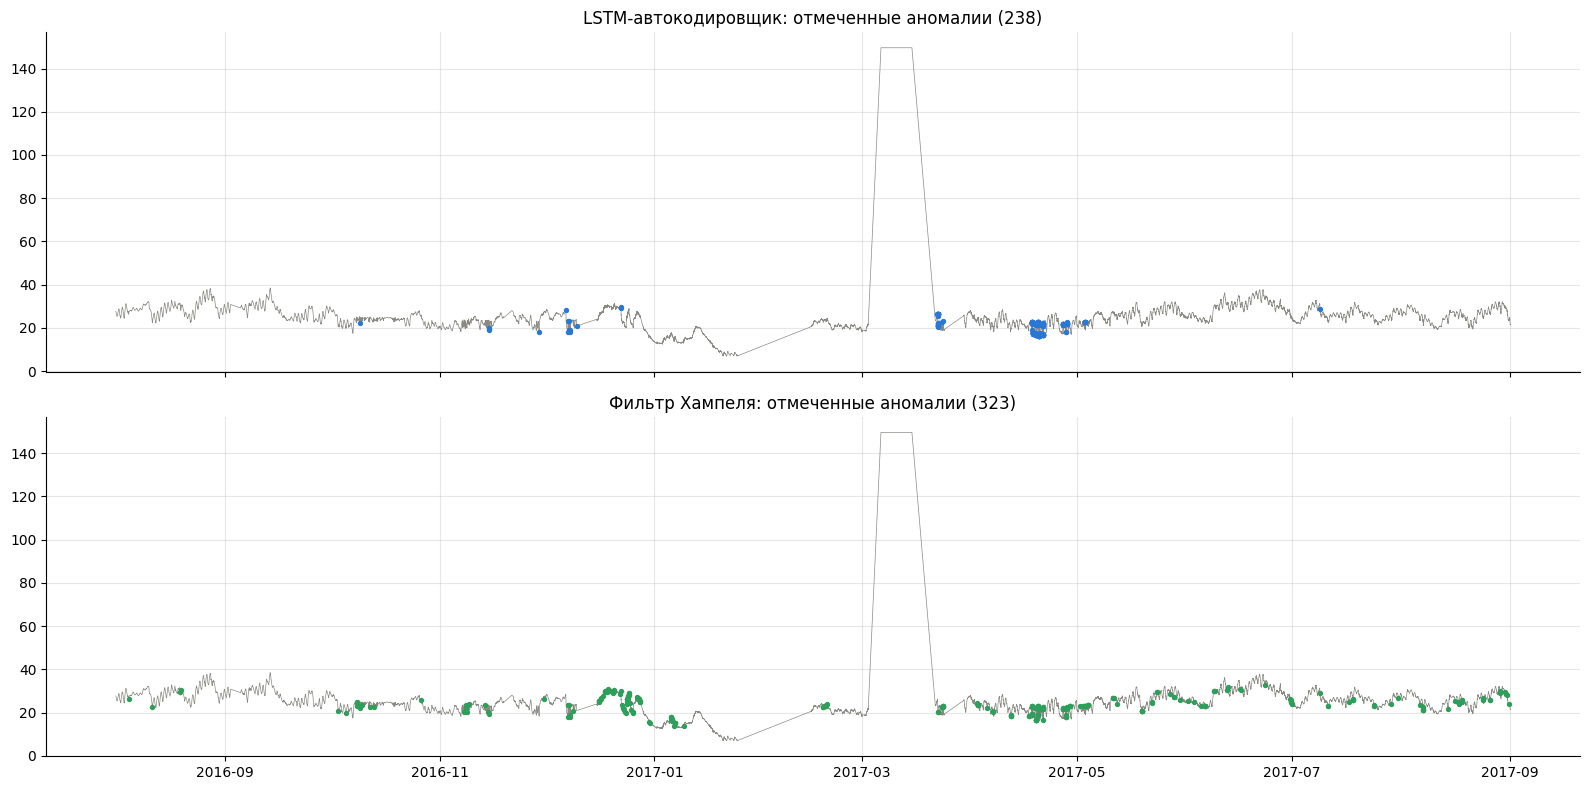

In [12]:
def label_measurements(df):
    # Размечает каждое исходное показание: 1 — аномалия, 0 — норма. Возвращает копию таблицы с двумя новыми столбцами
    grid_series = to_grid(df)
    grid_values = grid_series.to_numpy()
    # Номер точки сетки, в которую попадает каждое исходное показание
    pos = grid_series.index.get_indexer(df["Timestamp"].dt.floor(STEP))
    result = df.copy()
    for column, name in [("anomaly", "LSTM-автокодировщик"), ("anomaly_hampel", "Фильтр Хампеля")]:
        flags = detectors[name](grid_values) > thresholds[name]
        result[column] = flags[pos].astype(int)
    return result


labeled = label_measurements(raw)
print(f"Отмечено аномалий: автокодировщик {labeled['anomaly'].sum()}, "
      f"фильтр Хампеля {labeled['anomaly_hampel'].sum()} из {len(labeled)} показаний")
print("\nСамые большие и самые маленькие отмеченные автокодировщиком показания:")
flagged = labeled[labeled["anomaly"] == 1].sort_values("Value")
print(pd.concat([flagged.head(5), flagged.tail(5)])[["Timestamp", "Value"]].to_string(index=False))

# Весь ряд с отмеченными аномалиями
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for ax, (column, name) in zip(axes, [("anomaly", "LSTM-автокодировщик"), ("anomaly_hampel", "Фильтр Хампеля")]):
    ax.plot(labeled["Timestamp"], labeled["Value"], color=COLOR_SERIES, lw=0.5)
    marks = labeled[labeled[column] == 1]
    ax.scatter(marks["Timestamp"], marks["Value"], color=METHOD_COLORS[name], s=8, zorder=3)
    ax.set_title(f"{name}: отмеченные аномалии ({len(marks)})")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [13]:
# Сохранение результата: исходные столбцы плюс отметки аномалий
out_path = RESULTS_DIR / "sensor-fault-detection_labeled.csv"
labeled.to_csv(out_path, sep=";", index=False)
print("Результат сохранён:", out_path)

Результат сохранён: results\sensor-fault-detection_labeled.csv


## Выводы

1. **Решена задача** обнаружения аномалий в показаниях датчика температуры (62 629 показаний за август 2016 — август 2017) без разметки. Показания приведены к равномерной сетке с шагом 5 минут и разделены по времени: первые 70% — для обучения, последние 30% — для проверки. Обучены LSTM-автокодировщик (сжатие 4-часового отрезка в 16 чисел и восстановление обратно) и, для сравнения, построен фильтр Хампеля. Порог каждого метода выбран только по обучающим данным: аномалией считается точка, чья оценка выше, чем у 99,5% обучающих точек.

2. **Автокодировщик обучился быстро и устойчиво:** ошибка на обучении и контроле перестаёт снижаться примерно к 10-й эпохе (обучение — 0,006, контроль — 0,019). Ошибка на контроле выше, вероятно, потому что контрольные отрезки взяты из более позднего периода, весны 2017 года, с другим поведением температуры.

3. **Результаты на 80 искусственных сбоях** в проверочной части (3 864 точки со сбоем из 33 857):

   | Метод | Precision | Recall | F1 | ROC-AUC | PR-AUC |
   |---|---|---|---|---|---|
   | LSTM-автокодировщик | 0.640 | **0.179** | **0.280** | **0.842** | **0.563** |
   | Фильтр Хампеля | **0.765** | 0.062 | 0.114 | 0.564 | 0.224 |

   | Вид сбоя | Автокодировщик | Фильтр Хампеля |
   |---|---|---|
   | Скачок | 20 из 20 | 20 из 20 |
   | Залипание | 0 из 20 | 0 из 20 |
   | Дрейф | 20 из 20 | 16 из 20 |
   | Шум | 20 из 20 | 20 из 20 |

4. **Автокодировщик заметно лучше фильтра Хампеля** по всем метрикам, не зависящим от порога: ROC-AUC 0,842 против 0,564, PR-AUC 0,563 против 0,224. Он оценивает форму всего 4-часового отрезка и на дрейфе отмечает весь участок, где отклонение уже велико. Фильтр Хампеля сравнивает точку только с соседями за ±1 час, поэтому медленное уплывание показаний он не видит и на дрейфе срабатывает лишь на резких перепадах: на изломе в начале сбоя и на скачке обратно к настоящим показаниям в конце. Этот скачок — особенность вставленного сбоя, из-за него же отметки автокодировщика продолжаются ещё 1–2 часа после конца дрейфа. Фильтр Хампеля чуть точнее в своих отметках (precision 0,765), но находит очень малую часть точек со сбоем.

5. **Recall обоих методов низкий (0,18 и 0,06)**, хотя большинство сбоев найдено хотя бы одной точкой. Recall считается по точкам: у дрейфа отмечается только конец, где отклонение уже большое, а у шума — только самые сильные выбросы. Строгий порог (0,5% обучающих точек) уменьшает число ложных срабатываний, но пропускает начало и слабые участки сбоев. Порог можно снизить, если пропуск сбоя опаснее ложной тревоги.

6. **Залипание не обнаруживает ни один метод** (0 из 20). Постоянное значение — гладкий и легко восстанавливаемый сигнал: автокодировщик воспроизводит его без ошибки, а у фильтра Хампеля точка совпадает с медианой соседей. Для таких сбоев нужны дополнительные правила: контроль того, что показание не меняется слишком долго.

7. **Разметка настоящих данных:** автокодировщик отметил 238 показаний (0,38%), фильтр Хампеля — 323 (0,52%). Отметки автокодировщика сосредоточены на резких перепадах и участках с нехарактерным поведением (в основном апрель 2017 года), отметки фильтра Хампеля разбросаны по всему ряду на кратковременных колебаниях. В настоящих данных есть явный сбой, который не отметил ни один метод: 8 показаний 149,6 °C с 6 по 15 марта 2017 года (на графике выглядят как плато, потому что линия соединяет редкие показания). Это одиночные показания среди пропусков в несколько часов и суток: автокодировщику нужен непрерывный отрезок в 4 часа, фильтру Хампеля — соседние показания, поэтому оценки у них нет, и в разметке стоит 0. Для таких сбоев нужна проверка допустимого диапазона значений. Результат сохранён в `results/sensor-fault-detection_labeled.csv`: исходные столбцы и столбцы `anomaly` (автокодировщик) и `anomaly_hampel` (фильтр Хампеля).